In [32]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,classification_report
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier

In [33]:
# 1. Load dataset , inspect and check legitimate(0) and fraud(1)

df = pd.read_csv('creditcard.csv')
print("Dataset Shape",df.shape)
print(df.head())

# Check the balance between legitimate (0) and fraud (1)

print("\nClass Distribution:")
print(df['Class'].value_counts())
print("Percentage of fraud transactions:")
print((df['Class'].value_counts(normalize = True)*100).round(4))


Dataset Shape (284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

     

In [34]:
# 2. Scale features down and define X and y

scaler = StandardScaler()
df['scaled_amount'] = scaler.fit_transform(df[['Amount']])

X = df.drop(columns = ['Time','Amount','Class'])
y = df['Class']


In [35]:
# 3. Stratify training and testing set

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42,stratify = y)
print("Fraud cases in training set:",y_train.sum())
print("Fraud cases in testing set:",y_test.sum())


Fraud cases in training set: 394
Fraud cases in testing set: 98


In [36]:
# 4. Train logistic regression model and add weights
# class_weight='balanced' automatically increases penalty for missing fraud

lr_model = LogisticRegression(class_weight = 'balanced', max_iter = 100, random_state = 42)
lr_model.fit(X_train,y_train)

LogisticRegression(class_weight='balanced', random_state=42)

In [37]:
# 5. Evaluate using confusion matrix and classification report

y_pred = lr_model.predict(X_test)

print("Confusion Matrix")
print(confusion_matrix(y_test,y_pred))

print("\nClassification Report:")
print(classification_report(y_test,y_pred,target_names = ['Legitimate(0)','Fraud(1)']))

Confusion Matrix
[[55423  1441]
 [    8    90]]

Classification Report:
               precision    recall  f1-score   support

Legitimate(0)       1.00      0.97      0.99     56864
     Fraud(1)       0.06      0.92      0.11        98

     accuracy                           0.97     56962
    macro avg       0.53      0.95      0.55     56962
 weighted avg       1.00      0.97      0.99     56962



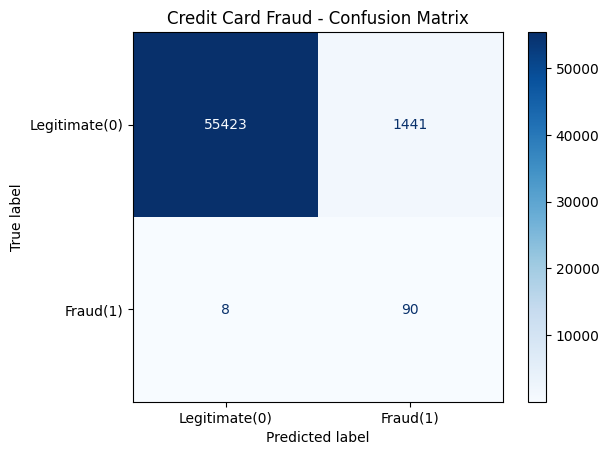

In [38]:
# 6. Plot the confusion matrix with clean labels

disp = ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels = ['Legitimate(0)','Fraud(1)'],cmap = 'Blues')
plt.title("Credit Card Fraud - Confusion Matrix")
plt.grid(False)
plt.show()


Random Forest Classification Report
               precision    recall  f1-score   support

Legitimate(0)       1.00      1.00      1.00     56864
     Fraud(1)       0.94      0.83      0.88        98

     accuracy                           1.00     56962
    macro avg       0.97      0.91      0.94     56962
 weighted avg       1.00      1.00      1.00     56962



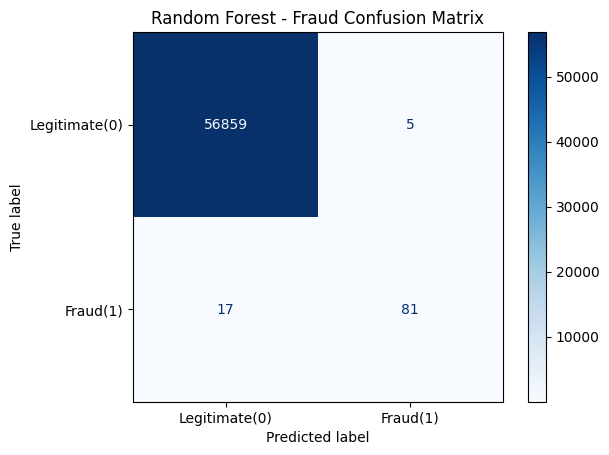

In [39]:
# 7. Evaluating Random Forest

# 1. Train Random Forest (using 100 decision trees)
rf_classifier = RandomForestClassifier(n_estimators = 100,random_state = 42, n_jobs=-1)
rf_classifier.fit(X_train,y_train)

# 2. Predict on the test set
rf_pred = rf_classifier.predict(X_test)

# 3. Print the classification metrics
print("\nRandom Forest Classification Report")
print(classification_report(y_test,rf_pred,target_names = ['Legitimate(0)','Fraud(1)']))

# 4. Display the confusion matrix

ConfusionMatrixDisplay.from_predictions(y_test,rf_pred,display_labels = ['Legitimate(0)','Fraud(1)'],cmap = 'Blues')
plt.title("Random Forest - Fraud Confusion Matrix")
plt.grid(False)
plt.show()